In [21]:
import kagglehub
import os
import pandas as pd

# Point to the cached dataset directory
dataset_path = kagglehub.dataset_download("prosperchuks/health-dataset")

# Load hypertension_data.csv
df = pd.read_csv(os.path.join(dataset_path, "hypertension_data.csv"))

In [22]:
df.head()

df.describe()

null_counts = df.isnull().sum()

print("Null counts in each column: {}".format(null_counts))

Null counts in each column: age          0
sex         25
cp           0
trestbps     0
chol         0
fbs          0
restecg      0
thalach      0
exang        0
oldpeak      0
slope        0
ca           0
thal         0
target       0
dtype: int64


In [23]:
import seaborn as sns

df.corr()['target']['sex']
df = df.drop(columns=['sex'])


In [ ]:
from sklearn.model_selection import train_test_split


X = df.drop(columns=['target'])
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)




Clean dataset shape: (302, 12)


In [25]:
from sklearn.preprocessing import StandardScaler

cols_to_scale = ['trestbps', 'chol', 'thalach', 'oldpeak']

scaler = StandardScaler()

# Fit ONLY on X_train to prevent data leakage, then transform both
X_train[cols_to_scale] = scaler.fit_transform(X_train[cols_to_scale])
X_test[cols_to_scale] = scaler.transform(X_test[cols_to_scale])

In [26]:
X_train.corrwith(y_train).sort_values(ascending=False)

cp          0.432417
thalach     0.416169
slope       0.347017
restecg     0.139828
age        -0.027649
fbs        -0.034975
chol       -0.080770
trestbps   -0.146256
thal       -0.364020
ca         -0.407038
oldpeak    -0.434259
exang      -0.440170
dtype: float64

<Axes: >

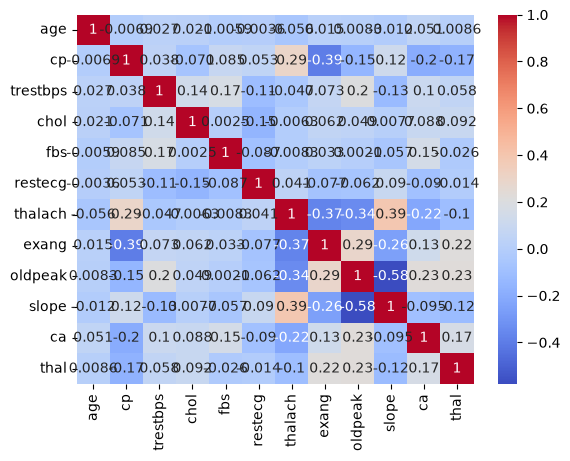

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.heatmap(X_train.corr(), annot=True, cmap='coolwarm')

In [28]:
clinical_cols = [col for col in X_train.columns if col != 'age']
print("Total rows:", len(df))
print("Unique patient profiles:", df[clinical_cols].drop_duplicates().shape[0])

Total rows: 26083
Unique patient profiles: 302


In [ ]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

# 1. Initialize the model (n_jobs=-1 uses all your CPU cores)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)

# 2. Train on the scaled training data
rf_model.fit(X_train, y_train)

# 3. Predict on the test data
y_pred = rf_model.predict(X_test)

# 4. Evaluate performance
print(classification_report(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print(accuracy_score(y_test, y_pred))




              precision    recall  f1-score   support

           0       1.00      0.99      1.00      2337
           1       0.99      1.00      1.00      2880

    accuracy                           1.00      5217
   macro avg       1.00      1.00      1.00      5217
weighted avg       1.00      1.00      1.00      5217

Confusion Matrix:
 [[2321   16]
 [   0 2880]]
0.9969331033160821


Allah akbar 3la el data Leakage

In [30]:
# Keep only the 302 real unique clinical records and drop the corrupted 'age' column
df_clean = df.drop_duplicates(subset=clinical_cols).drop(columns=['age']).copy()
print("Clean dataset shape:", df_clean.shape)


Clean dataset shape: (302, 12)


In [32]:
x = df_clean.drop(columns=['target'])
y = df_clean['target']

X_train_clean, X_test_clean, y_train_clean, y_test_clean = train_test_split(x, y, test_size=0.2, random_state=42)


In [33]:
rf_model_clean = RandomForestClassifier(n_estimators=100, max_depth=3, random_state=42, n_jobs=-1)

rf_model_clean.fit(X_train_clean, y_train_clean)

# 3. Predict on the test data
y_pred = rf_model_clean.predict(X_test_clean)

# 4. Evaluate performance
print(classification_report(y_test_clean, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test_clean, y_pred))
print(accuracy_score(y_test_clean, y_pred))


              precision    recall  f1-score   support

           0       0.88      0.79      0.84        29
           1       0.83      0.91      0.87        32

    accuracy                           0.85        61
   macro avg       0.86      0.85      0.85        61
weighted avg       0.86      0.85      0.85        61

Confusion Matrix:
 [[23  6]
 [ 3 29]]
0.8524590163934426
